# Exercise 1: Business cycle correlations

For this exercise, you'll be using macroeconomic data from the folder `data/FRED`.

The monthly files contain the following variables:

| Variable | Description |
|----------|-------------|
| `DATE` | Month of observation. |
| `CPI` | Consumer Price Index (1982–1984 = 100). |
| `UNRATE` | Unemployment rate, in percent. |
| `FEDFUNDS` | Effective federal funds rate, in percent. |
| `REALRATE` | One-year real interest rate, in percent. |
| `LFPART` | Labor force participation rate, in percent. |

## Part 1 — Loading and concatenating data

1. There are seven decade-specific files named `FRED_monthly_YYYY.csv` where
   `YYYY` identifies the decade by its first year (`YYYY` takes on the values
   1950, 1960, ..., 2010). Write a loop that reads in all seven files as
   DataFrames and stores them in a list.

   *Hint:* Recall from the lecture that you should use
   `pd.read_csv(..., parse_dates=['DATE'])` to automatically parse strings
   stored in the `DATE` column as dates.

2. Use
   [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
   to concatenate these data sets into a single `DataFrame` and set the
   `DATE` column as the index.

PART 1

In [1]:
import pandas as pd

#creating a path to the file
DATA_PATH = '../../data'

#creating a list to store the files in
file_lst = []

#looping over the files by years and storing the data in a list
for i in range(1950, 2011, 10):
    file = f'{DATA_PATH}/FRED/FRED_monthly_{i}.csv'
    df = pd.read_csv(file, parse_dates = ['DATE'])
    file_lst.append(df)



PART2

In [2]:
#creating the dataframe by concatenating the list
dataframe = pd.concat(file_lst)

In [3]:
#setting 'date' as the index
dataframe = dataframe.set_index('DATE')

## Part 2 — Merging GDP

You realize that your data set does not include GDP since this variable is only
reported at a quarterly frequency.
The file contains real GDP, which adjusts for changes in prices.
Load the GDP data from the file `GDP.csv` and merge it with your monthly data
using an _inner join_.

Explain what happens to the number of observations when you merge the monthly
and quarterly data sets.

In [4]:
#locating and reading in the datafile
file  = f'{DATA_PATH}/FRED/GDP.csv'
df = pd.read_csv(file, parse_dates = ['DATE'])



In [5]:
#mergin the data with the existing frame for months and using the function 'inner'
df_merge = pd.merge(dataframe, df, on = 'DATE', how = 'inner')
df_merge = df_merge.set_index('DATE')

Mergeing monthly and quarterly with the 'inner' command shortens the dataframe to only include the data with overlapping keys. In this case, since GDP is only reported quarterly, the dataset will limit the observations of all keys to quarterly even though there exists data for monthly observations.

## Part 3 — GDP growth and unemployment

GDP measures how much an economy produces, and `UNRATE` is the unemployment
rate. We want to explore how changes in these two variables are related.

1. Create a _new_ `DataFrame` containing percent changes in GDP and
   percentage-point changes in `UNRATE`. 
   
   - Compute GDP growth with
      [`pct_change()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pct_change.html)
      and multiply by 100 to convert to a percentage. 
   
   - Compute changes in unemployment with
      [`diff()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.diff.html).
      For example, an increase in unemployment from 6% to 7% is a change of 1 percentage point.

2. Use
   [`corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html)
   to compute the correlation between GDP growth and changes in
   unemployment. What do the sign and magnitude of the correlation coefficient
   tell you?
   
3. Create a scatter plot with GDP growth on the horizontal axis and the change
   in unemployment on the vertical axis. Each point should represent one
   quarter. Add horizontal and vertical lines at zero.
   Where are the quarters in which GDP falls and unemployment rises?
   Does unemployment always rise when GDP falls?

PART 1

In [ ]:
#making a dataframe with changes in GDP
df_changes = df_merge[['GDP']].pct_change()*100

#compute the changes in unemployment and adding the column to the dataframe
df_changes['UNRATE'] = df_merge['UNRATE'].diff()

df_changes.head(5)


,GDP,UNRATE
DATE,,
1950-01-01,NaN,NaN
1950-04-01,3.051873,-0.7
1950-07-01,3.863176,-0.8
1950-10-01,1.915495,-0.8
1951-01-01,1.359800,-0.5


PART 2

In [8]:
#Computing the correlation between BDP growth and changes in unemployment 
df_changes.corr()

,GDP,UNRATE
GDP,1.000000,-0.564872
UNRATE,-0.564872,1.000000


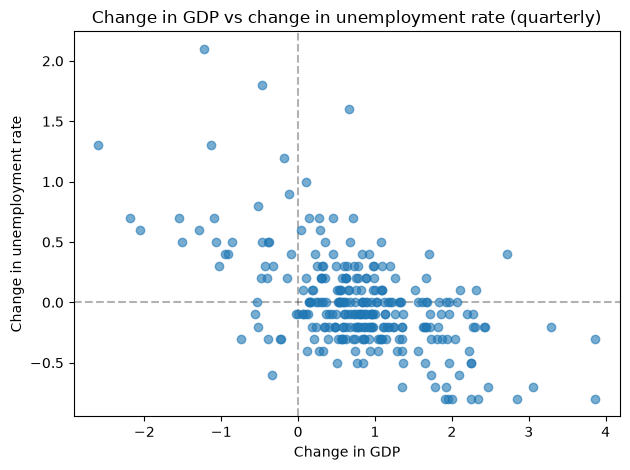

In [16]:
import matplotlib.pyplot as plt

plt.scatter(df_changes['GDP'], df_changes['UNRATE'], alpha = 0.6, zorder = 2)
plt.axhline(0, c = 'black', zorder = 1, ls = '--', alpha = 0.3)
plt.axvline(0, c = 'black', zorder = 1, ls = '--', alpha = 0.3)
plt.xlabel('Change in GDP')
plt.ylabel('Change in unemployment rate')
plt.title('Change in GDP vs change in unemployment rate (quarterly)')
plt.tight_layout()

***
# Exercise 2: Loading many data files

Python can find files matching a pattern using
[`glob.glob()`](https://docs.python.org/3/library/glob.html).

Load the seven decade files `FRED_monthly_YYYY.csv` in the local `data/FRED`
folder using `glob.glob()`. Match names starting with `FRED_monthly_1` or
`FRED_monthly_2`, and store the DataFrames in a list. Parse `DATE` as dates and
set it as the index. Concatenate the list along the row axis and sort by date.

In [23]:
import glob
import pandas as pd

#making an empty list to store the dataframes
data_frames = []

#using the glob.glob command to store all the corresponding files in a variable
files = glob.glob(f'{DATA_PATH}/FRED/FRED_monthly_*.csv')

#looping over all the files in files to read them in and storing them in the empty list
for file in files:
    df = pd.read_csv(file, parse_dates = ['DATE'], index_col = 'DATE')
    data_frames.append(df)

#concatenating the dataframes in the list to make one final dataframe
final_df = pd.concat(data_frames, axis = 0)

In [24]:
final_df

,CPI,UNRATE,FEDFUNDS,REALRATE,LFPART,INFLATION
DATE,,,,,,
1950-01-01,23.5,6.5,NaN,NaN,58.9,NaN
1950-02-01,23.6,6.4,NaN,NaN,58.9,NaN
1950-03-01,23.6,6.3,NaN,NaN,58.8,NaN
1950-04-01,23.6,5.8,NaN,NaN,59.2,NaN
1950-05-01,23.8,5.5,NaN,NaN,59.1,NaN
...,...,...,...,...,...,...
1969-08-01,36.9,3.5,9.2,NaN,60.3,NaN
1969-09-01,37.1,3.7,9.2,NaN,60.3,NaN
1969-10-01,37.3,3.7,9.0,NaN,60.4,NaN


***
# Exercise 3: Weekly returns of the Magnificent Seven

In this exercise, you are asked to analyze the weekly stock market returns of the
so-called Magnificent Seven, which are some of the most successful tech companies
of the last few decades:
Apple (AAPL), Amazon (AMZN), Alphabet/Google (GOOGL), Meta (META), Microsoft (MSFT), Nvidia (NVDA), and Tesla (TSLA).

The data for this exercise is located in the folder `data/stockmarket/`.
Each stock file contains the following variables:

| Variable | Description |
|----------|-------------|
| `Date` | Trading date. |
| `Open` | Opening stock price for the trading day. |
| `Close` | Closing stock price for the trading day. |

## Part 1 — Loading and computing returns

For each of the seven stocks listed above, there is a corresponding CSV file in
this directory based on the ticker symbol. For example, the file for Apple is `AAPL.csv`.

1. For each ticker symbol, load the corresponding CSV file and make sure that
   the `Date` column is set as the index.

   The DataFrame has two columns, `Open` and `Close`, which contain the
   opening and closing prices for each trading day.

2. Use
   [`resample()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.resample.html)
   to resample the daily data to a weekly frequency by specifying
   `resample('W')`, and compute the weekly returns in percent:

   $$
   \text{Weekly returns} =
   \frac{\text{Close price on last day} - \text{Open price on first day}}
        {\text{Open price on first day}} \times 100
   $$

   *Hint:* You can obtain the first and last observations using the
   [`first()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.first.html)
   and
   [`last()`](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.Resampler.last.html)
   methods.

3. Append these returns to a list so you can merge them into a single DataFrame
   later.

In [64]:
import pandas as pd

# List of ticker symbols for the 7 stocks
symbols = ['AAPL', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']

# List to store weekly returns
returns = []

for symbol in symbols:
    # Load this file and use Date as the row index
    filename = f'{DATA_PATH}/stockmarket/{symbol}.csv'
    df = pd.read_csv(filename, parse_dates=['Date'], index_col='Date')

    # Resample to weekly frequency, store first and last prices
    first = df.resample('W')['Open'].first()
    last = df.resample('W')['Close'].last()

    # Compute weekly percentage returns
    ret = (last - first) / first * 100.0

    # Give series the corresponding ticker symbol as name
    ret.name = symbol

    returns.append(ret)

## Part 2 — Merging weekly returns

Merge the weekly returns into a single DataFrame, keeping the intersection of
dates available for all 7 stocks. Discard the first and last week of the merged
DataFrame, since the data do not cover a full trading week for every stock.

*Hint:* This can be achieved using either
[`pd.concat(..., join='inner')`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html),
[`pd.merge()`](https://pandas.pydata.org/docs/reference/api/pandas.merge.html),
or
[`DataFrame.join()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.join.html).

In [ ]:
#merging the weekly returns into one dataframe
df_returns = pd.concat(returns, axis = 1, keys = symbols, join = 'inner')

#discarding the first and last week from the dataset
df_returns = df_returns.iloc[1:-1]

## Part 3 — Pairwise correlations

Finally, you are interested in how the weekly returns are correlated across the
7 stocks.

1. Compute and report the pairwise correlations using
   [`DataFrame.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html).

2. Create a figure with a 7-by-7 grid of subplots showing the pairwise scatter
   plots of weekly returns for each combination of stocks.

   You can do this either with the
   [`scatter_matrix()`](https://pandas.pydata.org/docs/reference/api/pandas.plotting.scatter_matrix.html)
   function contained in `pandas.plotting`, or manually build the figure using
   Matplotlib functions.

3. **[Advanced]** Add the corresponding correlation coefficient to each
   off-diagonal subplot (e.g., about 0.43 for AAPL and AMZN).

Part 1

In [75]:
#computing pairwise correlations
corr = df_returns.corr()

Part 2

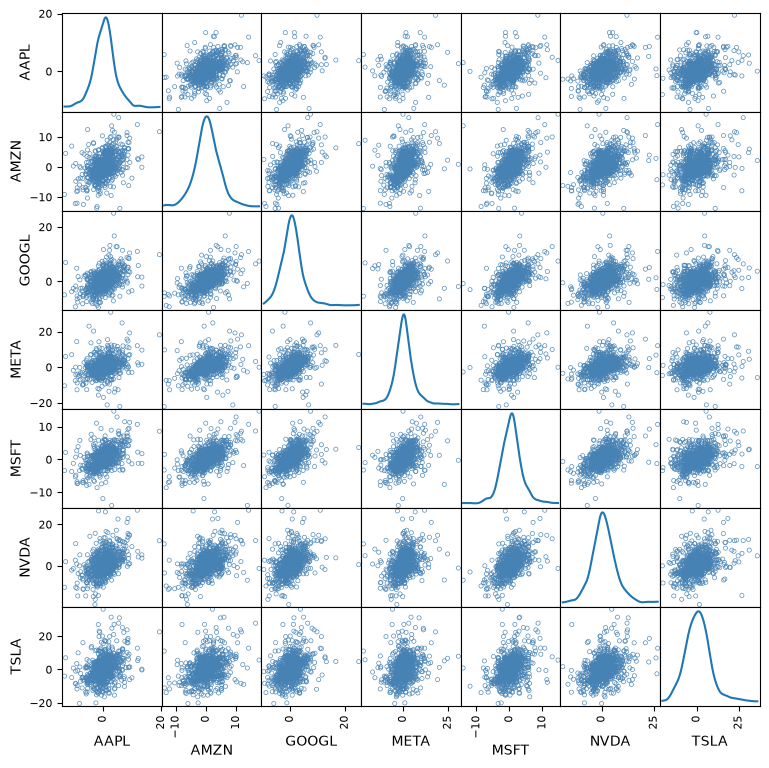

In [76]:
#creating a scatterplot with the corelations between the stock returns
from pandas.plotting import scatter_matrix

axes = scatter_matrix(
    df_returns,
    figsize = (9,9),
    c = 'none',
    edgecolors = 'steelblue',
    alpha = 0.9,
    lw = 0.5,
    diagonal = 'kde',
)

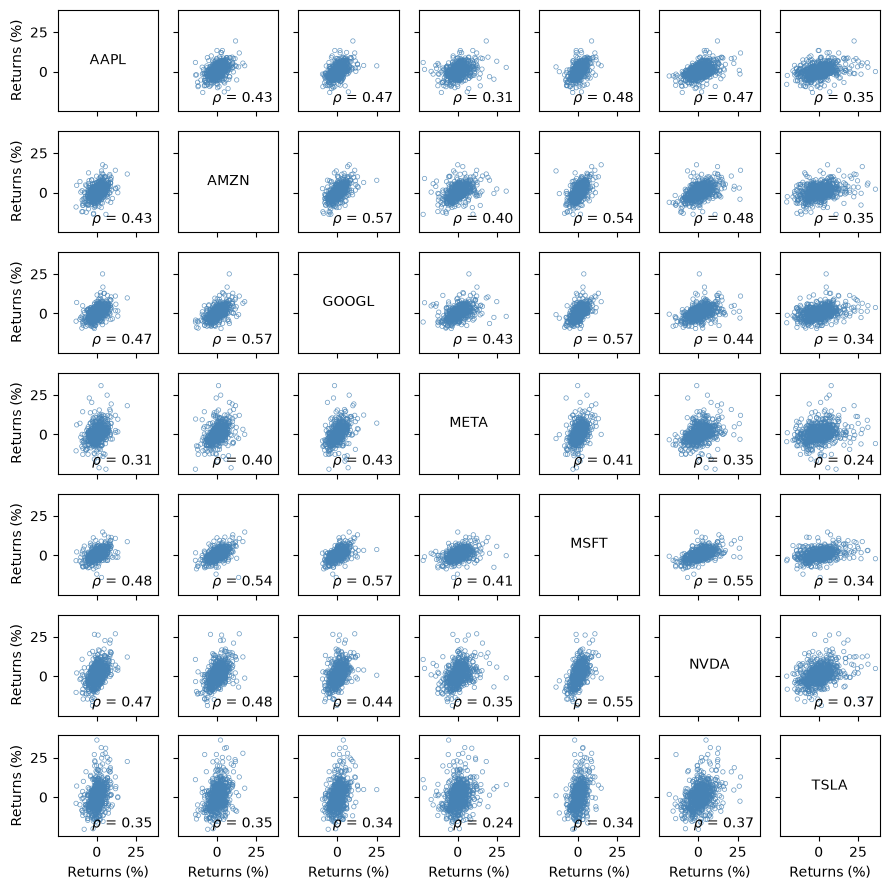

In [81]:
#alternative
import matplotlib.pyplot as plt

tickers = df_returns.columns.to_list()

n = len(tickers)

fig, axes = plt.subplots(n, n, figsize = (9, 9), sharey = True, sharex = True )
#iterate over rows and columns 

for i in range(n):
    for j in range (n):
        ax = axes[i, j]

        if i == n-1:
            ax.set_xlabel('Returns (%)')
        if j == 0:
            ax.set_ylabel('Returns (%)')

        if i == j:
            ax.text(
                0.5, 0.5, tickers[i], transform = ax.transAxes, va = 'center', ha = 'center'
            )
            continue

        x_values = df_returns.iloc[:,j]
        y_values = df_returns.iloc[:,i]

        ax.scatter(
            x_values,
            y_values,
            color = 'none',
            edgecolors = 'steelblue',
            s = 10,
            alpha = 0.8,
            lw = 0.5,
        )

        ax.text(
            0.95,
            0.05,
            rf'$\rho$ = {corr.iloc[i, j]:.2f}',
            transform = ax.transAxes,
            va = 'bottom',
            ha = 'right',
        )


fig.tight_layout()



***
# Exercise 4: Inflation expectations and past inflation

In this exercise, we explore whether people's expectations about future inflation
are related to inflation they have recently experienced. Inflation measures how
much prices rise, while deflation means that prices fall.

We use a 10% sample of
[Survey of Consumer Expectations (SCE)](https://www.newyorkfed.org/microeconomics/sce),
a survey of US consumers administered by the Federal Reserve Bank of New York.
The files in `data/SCE_10pct/` contain individual responses from June 2013 through
September 2025. Missing values and extreme forecasts have already been removed.
Each row represents one respondent in one survey month.

| Variable | Description |
|----------|-------------|
| `userid` | Respondent identifier. |
| `date` | First day of the survey month. |
| `female` | Gender indicator: 0 = male, 1 = female. |
| `infl_1y` | Expected inflation over the next 12 months, in percent. |

For example, `infl_1y = 3.5` means that the respondent expects prices to rise by
3.5% over the next 12 months. A negative value indicates expected deflation.

## Part 1 — Loading and grouping

1. Write a loop to load the 13 annual files `SCE_2013.csv`, ..., `SCE_2025.csv`
   into a list of DataFrames. Parse `date` as a date column.

   *Hint:* Use `pd.read_csv(..., parse_dates=['date'])` to automatically parse strings stored in the `date` column as dates.

2. Concatenate these DataFrames into a single DataFrame using 
   [`pd.concat()`](https://pandas.pydata.org/docs/reference/api/pandas.concat.html)
   and sort the rows by `date` and `userid`.

3. Group by `date` and `female` to calculate mean expected inflation for each
   month and gender. Keep the result as a DataFrame, rename `infl_1y` to
   `expected`, and use `reset_index()` to make the grouping variables regular
   columns again.

   *Hint:* Use
   [`rename()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.rename.html)
   to rename columns.

In [110]:
#doing the same operation as in the first exercise
data_lst = []
for i in range(2013, 2026):
    file = f'{DATA_PATH}/SCE_10pct/SCE_{i}.csv'
    df = pd.read_csv(file, parse_dates = ['date'])
    data_lst.append(df)

In [112]:
#Putting the dataframes into the same hsared dataframe
df = pd.concat(data_lst, ignore_index = True)

df = df.sort_values(['date', 'userid'])


In [118]:
#compute the average by gender and month
df_expect = df.groupby(['date', 'female'])[['infl_1y']].mean()

df_expect = df_expect.rename(columns={'infl_1y': 'expected'})

df_expect = df_expect.reset_index()

## Part 2 — Past inflation and merging

The Consumer Price Index (CPI) measures the overall level of consumer prices.
For example, if the CPI rises from 100 to 104 over 12 months, inflation over that
period is 4%.

1. Load `data/FRED/CPI.csv`, parse `DATE` as dates, and rename it to `date`.
2. Compute inflation over the preceding 12 months and store it in a new column
   named `past_inflation`:
   $$
   \text{Past inflation}_t =
   \left(\frac{CPI_t}{CPI_{t-12}} - 1\right) \times 100.
   $$
   Here, $t$ is the current month and $t-12$ is the same month one year earlier.

   *Hint:* Use `pct_change(periods=12)` and multiply by 100. Compute this change
   on the monthly CPI data before merging.
3. Use `pd.merge()` to merge `past_inflation` with the monthly expectations
   from Part 1, matching on the `date` column. Keep both genders for
   every survey month. Why do men and women receive the same observed inflation
   rate in each month?

In [130]:
file = f'{DATA_PATH}/FRED/CPI.csv'

data = pd.read_csv(file, parse_dates = ['DATE'])
data = data.set_index('DATE')

df_infl = data[['CPI']].pct_change(periods = 12)*100

df_infl = df_infl.reset_index().rename(columns = {'DATE': 'date', 'CPI': 'past'})

df_expect = pd.merge(df_expect, df_infl, on='date', how='inner')

df_expect

,date,female,expected,CPI_x,CPI_y,past
0,2013-06-01,0,4.458333,1.706783,1.706783,1.706783
1,2013-06-01,1,7.913462,1.706783,1.706783,1.706783
2,2013-07-01,0,5.420290,1.881015,1.881015,1.881015
3,2013-07-01,1,5.000000,1.881015,1.881015,1.881015
4,2013-08-01,0,4.840404,1.565898,1.565898,1.565898
...,...,...,...,...,...,...
291,2025-07-01,1,3.774074,2.742347,2.742347,2.742347
292,2025-08-01,0,5.076000,2.929004,2.929004,2.929004
293,2025-08-01,1,8.490566,2.929004,2.929004,2.929004
294,2025-09-01,0,3.782692,3.018748,3.018748,3.018748


## Part 3 — Plotting and interpretation

1. Create a figure with two scatter plots, one for men and one for women.
   Put observed inflation over the *past* 12 months on the horizontal axis
   and mean expected inflation over the *next* 12 months on the vertical axis.
   Each point should represent one month.

   Add axis labels and panel titles. Use the same axis limits in both panels so
   that we can compare the groups.

2. Are higher past inflation rates associated with higher inflation expectations?
   Does the relationship differ by gender?